# NaiveBayes
## 1. Import libraries and necessary files, data

In [1]:
import sys
from pathlib import Path
import numpy as np

# Lấy thư mục gốc của project (thư mục cha của thư mục notebooks hiện tại)
project_dir = Path.cwd().parent

# Thêm thư mục gốc vào sys.path để Python nhận diện các module
sys.path.insert(0, str(project_dir))

# Import các module và dữ liệu
from src.algorithm.NaiveBayes import NaiveBayes,gaussian_log_pdf
from data.preprocessing import (
    X_train_scaled,
    X_val_scaled,
    X_test_scaled,
    y_train,
    y_val,
    y_test,
)

## 2. Train Model and Classification report
### 2.1 Gaussian_log_pdf

In [2]:
from sklearn.metrics import classification_report
nb_model = NaiveBayes(log_pdf = gaussian_log_pdf)
# train the model
nb_model.fit(X_train_scaled, y_train)
y_pred = nb_model.predict(X_test_scaled)
print("Đã huấn luyện mô hình Naive Bayes thành công!")

print("Classification Report:")
print(classification_report(y_test, y_pred, target_names= nb_model.classes.astype(str)))

Đã huấn luyện mô hình Naive Bayes thành công!
Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.88      0.84       980
           1       0.83      0.96      0.89      1135
           2       0.92      0.28      0.43      1032
           3       0.73      0.38      0.50      1010
           4       0.89      0.22      0.36       982
           5       0.58      0.06      0.10       892
           6       0.62      0.94      0.75       958
           7       0.87      0.28      0.42      1028
           8       0.29      0.61      0.39       974
           9       0.36      0.95      0.52      1009

    accuracy                           0.56     10000
   macro avg       0.69      0.55      0.52     10000
weighted avg       0.70      0.56      0.53     10000



#### 2.1.1 PCA giảm chiều dữ liệu 

Số chiều:  10 | Accuracy: 76.33%
Số chiều:  30 | Accuracy: 85.69%
Số chiều:  50 | Accuracy: 87.10%
Số chiều: 100 | Accuracy: 86.96%
Số chiều: 150 | Accuracy: 85.66%
Số chiều: 200 | Accuracy: 84.67%
Số chiều: 300 | Accuracy: 81.98%


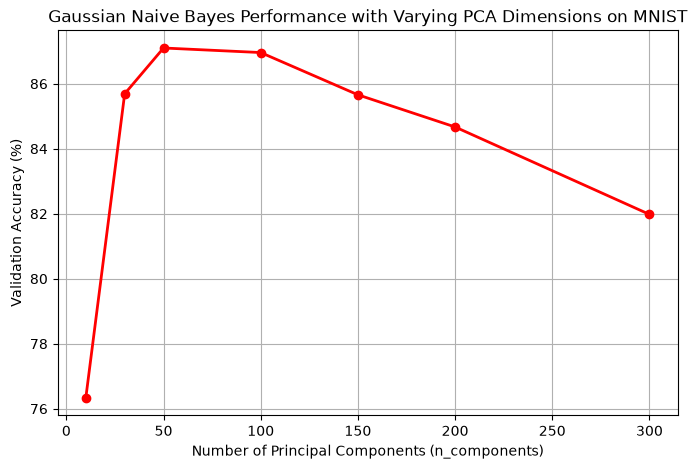

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

# Varying the number of PCA components and evaluating the performance of the Naive Bayes model
n_components_list = [10, 30, 50, 100, 150, 200, 300]
accuracies = []

for n_comp in n_components_list:
    # initial `PCA` with the specified number of components
    pca = PCA(n_components=n_comp)
    X_train_pca = pca.fit_transform(X_train_scaled)  # reduce the training data to n_comp dimensions
    X_val_pca = pca.transform(X_val_scaled)  # trans form the validation data to the same PCA space

    # training the Naive Bayes model on the PCA-reduced data
    model = NaiveBayes(log_pdf=gaussian_log_pdf)
    model.fit(X_train_pca, y_train)

    # 3. Dự đoán và tính độ chính xác
    y_pred = model.predict(X_val_pca)
    acc = accuracy_score(y_val, y_pred)
    accuracies.append(acc)
    print(f"Số chiều: {n_comp:3d} | Accuracy: {acc * 100:.2f}%")

# draw the performance plot
plt.figure(figsize=(8, 5))
plt.plot(
    n_components_list,
    [a * 100 for a in accuracies],
    marker='o',
    color='r',
    linestyle='-',
    linewidth=2,
)
plt.title(
    'Gaussian Naive Bayes Performance with Varying PCA Dimensions on MNIST'
)
plt.xlabel('Number of Principal Components (n_components)')
plt.ylabel('Validation Accuracy (%)')
plt.grid(True)
plt.show()

## 2.2 Logistic Regression

In [4]:
from src.algorithm.Logistic_Regression import LogisticRegression
model: LogisticRegression = LogisticRegression(
    learning_rate = 0.1,
    n_epochs = 30,
    batch_size = 256,
    reg_strength = 0.0001,
    random_state = 42,
)
#Training using the training subset.
model.fit(X_train_scaled, y_train)

#Evaluate using the validation subset.
validation_accuracy: float = model.score(X_val_scaled, y_val)

#Display validation accuracy.
print(f"Validation accuracy: {validation_accuracy: .2%}")

Epoch 001/030 | Training loss:  0.493745
Epoch 002/030 | Training loss:  0.415636
Epoch 003/030 | Training loss:  0.382344
Epoch 004/030 | Training loss:  0.364118
Epoch 005/030 | Training loss:  0.350802
Epoch 006/030 | Training loss:  0.340709
Epoch 007/030 | Training loss:  0.333437
Epoch 008/030 | Training loss:  0.327545
Epoch 009/030 | Training loss:  0.322504
Epoch 010/030 | Training loss:  0.317848
Epoch 011/030 | Training loss:  0.314505
Epoch 012/030 | Training loss:  0.312388
Epoch 013/030 | Training loss:  0.308500
Epoch 014/030 | Training loss:  0.305709
Epoch 015/030 | Training loss:  0.304015
Epoch 016/030 | Training loss:  0.302093
Epoch 017/030 | Training loss:  0.300175
Epoch 018/030 | Training loss:  0.298125
Epoch 019/030 | Training loss:  0.296865
Epoch 020/030 | Training loss:  0.295511
Epoch 021/030 | Training loss:  0.294452
Epoch 022/030 | Training loss:  0.293076
Epoch 023/030 | Training loss:  0.291316
Epoch 024/030 | Training loss:  0.290452
Epoch 025/030 | 

## 2.3 MLP

In [12]:
from src.algorithm.MLP import MLP

mlp_model = MLP(n_epochs=50)

mlp_model.fit(X_train_scaled, y_train, X_val_scaled, y_val)

mlp_y_pred = mlp_model.predict(X_test_scaled)

y_test = np.asarray(y_test)
accuracy = np.mean(y_pred == y_test)

print("Test accuracy:", accuracy)

epoch  1 |   0.3s | train loss 0.3860 acc 0.8824 | val loss 0.3945 acc 0.8809
best accuracy: 0.8809
epoch  2 |   0.2s | train loss 0.2281 acc 0.9354 | val loss 0.2427 acc 0.9313
best accuracy: 0.9313
epoch  3 |   0.2s | train loss 0.2092 acc 0.9376 | val loss 0.2250 acc 0.9347
best accuracy: 0.9347
epoch  4 |   0.2s | train loss 0.1612 acc 0.9543 | val loss 0.1847 acc 0.9468
best accuracy: 0.9468
epoch  5 |   0.2s | train loss 0.1370 acc 0.9609 | val loss 0.1622 acc 0.9552
best accuracy: 0.9552
epoch  6 |   0.2s | train loss 0.1240 acc 0.9650 | val loss 0.1549 acc 0.9559
best accuracy: 0.9559
epoch  7 |   0.2s | train loss 0.1051 acc 0.9701 | val loss 0.1364 acc 0.9615
best accuracy: 0.9615
epoch  8 |   0.3s | train loss 0.1024 acc 0.9703 | val loss 0.1357 acc 0.9591
best accuracy: 0.9615
epoch  9 |   0.2s | train loss 0.0894 acc 0.9750 | val loss 0.1266 acc 0.9628
best accuracy: 0.9628
epoch 10 |   0.2s | train loss 0.0815 acc 0.9776 | val loss 0.1215 acc 0.9642
best accuracy: 0.9642


## 3. Ensemble method

In [ ]:
from src.algorithm.NaiveBayes import NaiveBayes, gaussian_log_pdf
from src.algorithm.Logistic_Regression import LogisticRegression
from src.algorithm.Ensemble import ManualStackingEnsemble

model_nb = NaiveBayes(log_pdf=gaussian_log_pdf)
model_lr = LogisticRegression()
ensemble = ManualStackingEnsemble(
    base_models=[model_nb, model_lr],
    meta_model=LogisticRegression(),
    cv_folds=5
)

# training the ensemble model and evaluating its performance on the test set
ensemble.fit(X_train_scaled, y_train)
accuracy = ensemble.evaluate(X_test_scaled, y_test)
print(f"Stacking Ensemble Accuracy trên MNIST: {accuracy * 100:.2f}%")


Epoch 001/030 | Training loss:  0.527268
Epoch 002/030 | Training loss:  0.435523
Epoch 003/030 | Training loss:  0.398562
Epoch 004/030 | Training loss:  0.377672
Epoch 005/030 | Training loss:  0.365683
Epoch 006/030 | Training loss:  0.352510
Epoch 007/030 | Training loss:  0.344613
Epoch 008/030 | Training loss:  0.336356
Epoch 009/030 | Training loss:  0.330892
Epoch 010/030 | Training loss:  0.325798
Epoch 011/030 | Training loss:  0.322196
Epoch 012/030 | Training loss:  0.318808
Epoch 013/030 | Training loss:  0.315429
Epoch 014/030 | Training loss:  0.312799
Epoch 015/030 | Training loss:  0.309763
Epoch 016/030 | Training loss:  0.308153
Epoch 017/030 | Training loss:  0.305456
Epoch 018/030 | Training loss:  0.303406
Epoch 019/030 | Training loss:  0.301475
Epoch 020/030 | Training loss:  0.300059
Epoch 021/030 | Training loss:  0.298362
Epoch 022/030 | Training loss:  0.296842
Epoch 023/030 | Training loss:  0.296627
Epoch 024/030 | Training loss:  0.295061
Epoch 025/030 | 